stacked lstm
Window = 13
LSTM = 16 → 8
Dense = 8

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

load data

In [2]:
df = pd.read_csv("ds18b20_data.csv")

temps = df["temperature_C"].values.reshape(-1, 1)

print(df.head())
print("Total readings:", len(df))

   timestamp  temperature_C
0     1630.0         26.625
1     4138.0         26.687
2     6646.0         26.750
3     9154.0         26.750
4    11662.0         26.750
Total readings: 2872


normalize

In [3]:
scaler = MinMaxScaler()
temps_scaled = scaler.fit_transform(temps)

print("Scaler min:", scaler.data_min_[0])
print("Scaler max:", scaler.data_max_[0])

Scaler min: 7.312
Scaler max: 38.938


seq

In [4]:
WINDOW = 13

X = []
y = []

for i in range(len(temps_scaled) - WINDOW):
    X.append(temps_scaled[i:i + WINDOW])
    y.append(temps_scaled[i + WINDOW])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2859, 13, 1)
y shape: (2859, 1)


train-test split

In [5]:
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))

Train samples: 2287
Test samples: 572


model

In [6]:
model = Sequential([
    Input(shape=(WINDOW, 1)),

    LSTM(16, return_sequences=True),
    LSTM(8),

    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()
print("Total Parameters:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 13, 16)         │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 8)              │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,033 (7.94 KB)

 Trainable params: 2,033 (7.94 KB)

 Non-trainable params: 0 (0.00 B)

Total Parameters: 2033


train

In [7]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - loss: 0.0468 - mae: 0.1214 - val_loss: 1.5026e-05 - val_mae: 0.0036
Epoch 2/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0016 - mae: 0.0212 - val_loss: 1.2355e-04 - val_mae: 0.0110
Epoch 3/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0015 - mae: 0.0204 - val_loss: 6.2121e-06 - val_mae: 0.0022
Epoch 4/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0014 - mae: 0.0182 - val_loss: 5.1997e-04 - val_mae: 0.0228
Epoch 5/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0012 - mae: 0.0162 - val_loss: 1.1298e-04 - val_mae: 0.0105
Epoch 6/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0012 - mae: 0.0155 - val_loss: 7.8972e-05 - val_mae: 0.0088
Epoch 7/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0011 - mae: 0.0159 - val_loss: 4.5755e-04 - val_mae: 0.0214
Epoch 8/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0010 - mae: 0.0148 - val_loss: 2.3343e-04 - val_mae: 0.0152
Epoch 9/

predict

In [8]:
y_pred_scaled = model.predict(X_test)

y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


eval metrics

In [9]:
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual) * 100
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"MAE : {mae:.6f} °C")
print(f"MSE : {mse:.6f}")
print(f"RMSE: {rmse:.6f} °C")
print(f"MAPE: {mape:.4f} %")
print(f"R²  : {r2:.6f}")

MAE : 0.045100 °C
MSE : 0.002900
RMSE: 0.053853 °C
MAPE: 0.1912 %
R²  : 0.968566


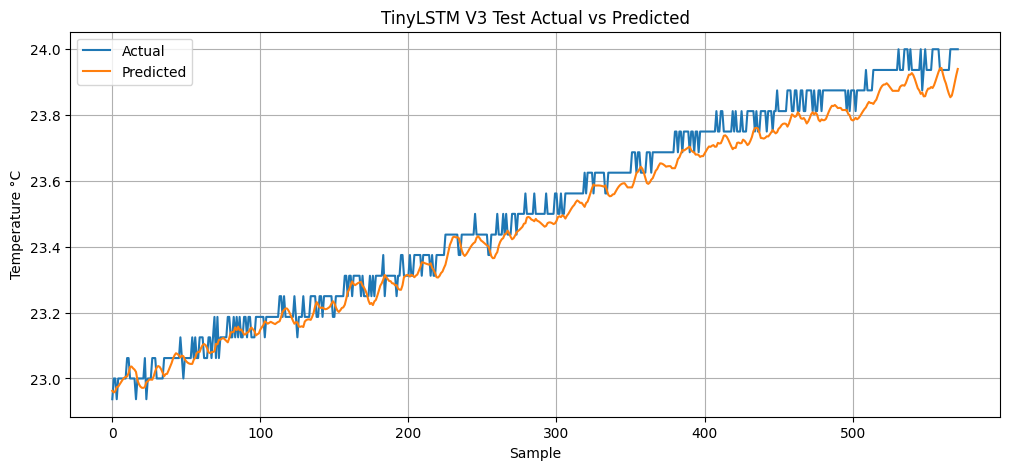

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual, label="Actual")
plt.plot(y_pred_actual, label="Predicted")

plt.title("TinyLSTM V3 Test Actual vs Predicted")
plt.xlabel("Sample")
plt.ylabel("Temperature °C")
plt.legend()
plt.grid(True)

plt.show()

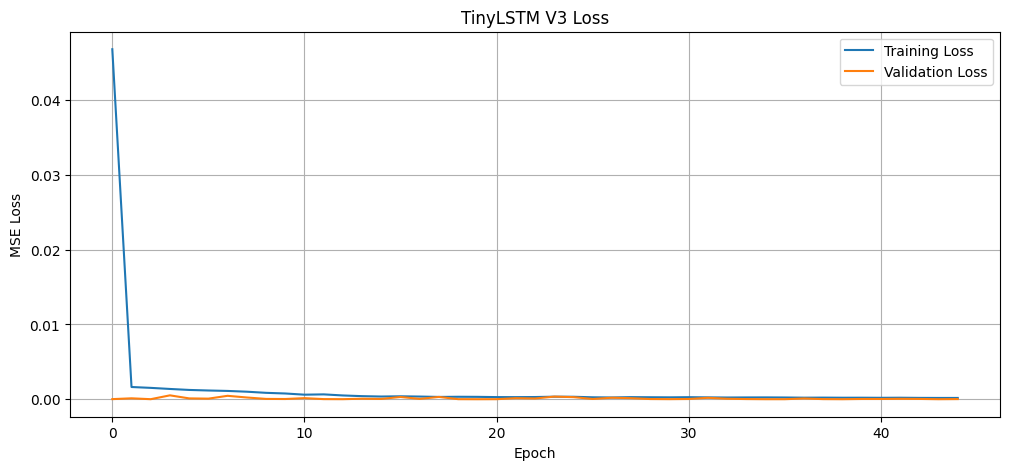

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("TinyLSTM V3 Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

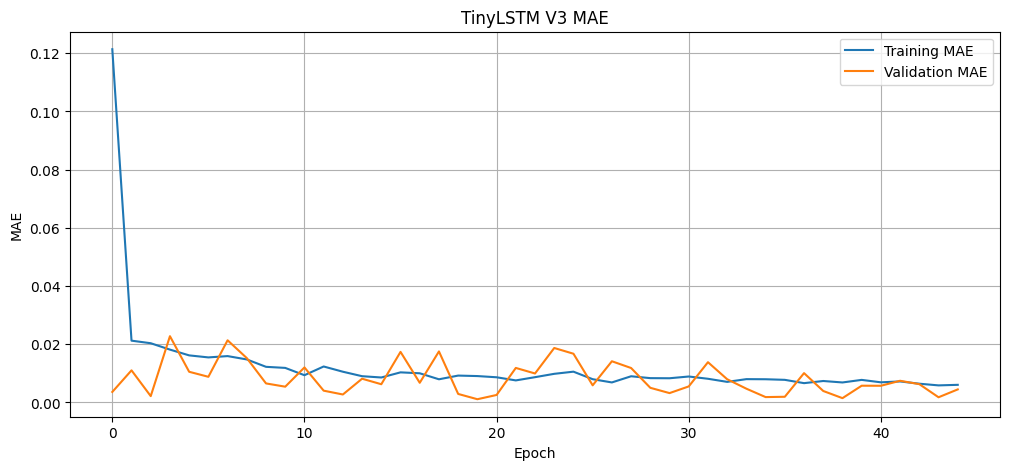

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("TinyLSTM V3 MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.show()

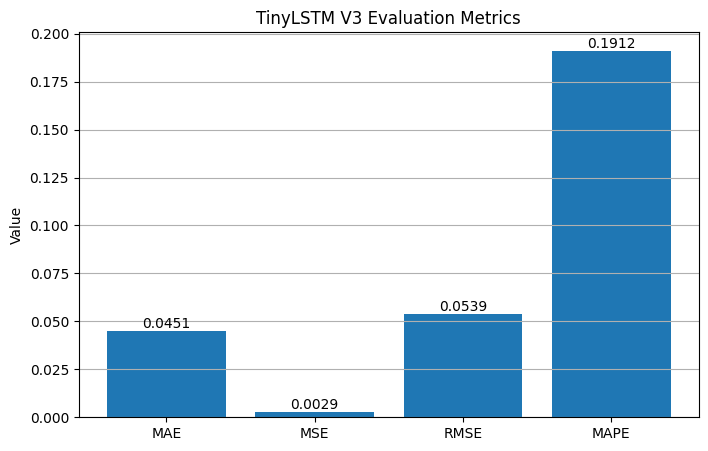

In [13]:
metric_names = ["MAE", "MSE", "RMSE", "MAPE"]
metric_values = [mae, mse, rmse, mape]

plt.figure(figsize=(8, 5))
plt.bar(metric_names, metric_values)

plt.title("TinyLSTM V3 Evaluation Metrics")
plt.ylabel("Value")
plt.grid(axis="y")

for i, v in enumerate(metric_values):
    plt.text(i, v, f"{v:.4f}", ha="center", va="bottom")

plt.show()

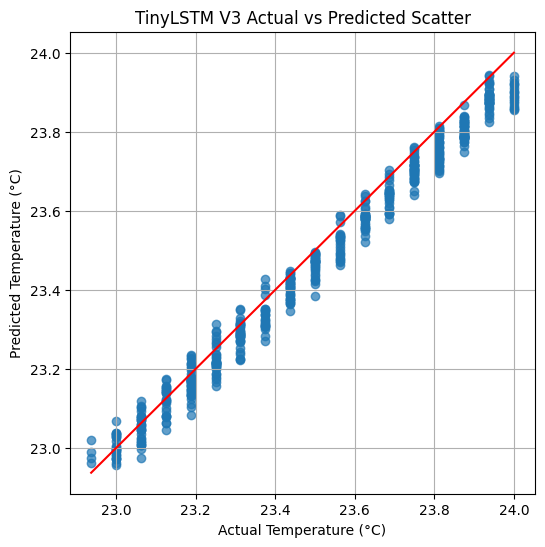

In [14]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test_actual,
    y_pred_actual,
    alpha=0.7
)

plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()],
    "r"
)

plt.title("TinyLSTM V3 Actual vs Predicted Scatter")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.grid(True)

plt.show()

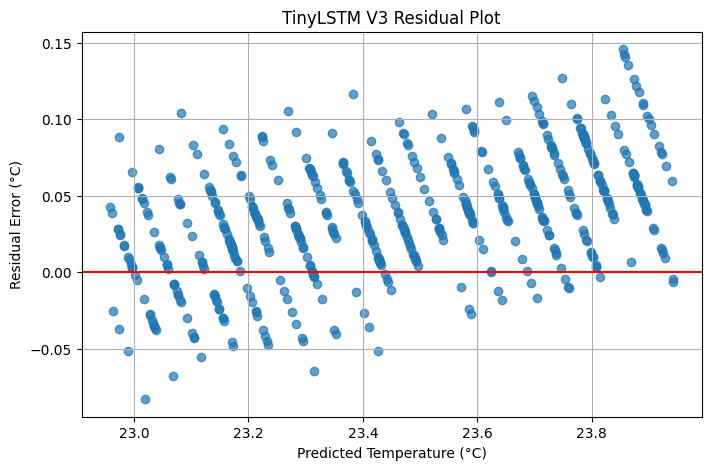

In [15]:
residuals = y_test_actual.flatten() - y_pred_actual.flatten()

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_actual,
    residuals,
    alpha=0.7
)

plt.axhline(0, color="red")

plt.title("TinyLSTM V3 Residual Plot")
plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual Error (°C)")
plt.grid(True)

plt.show()

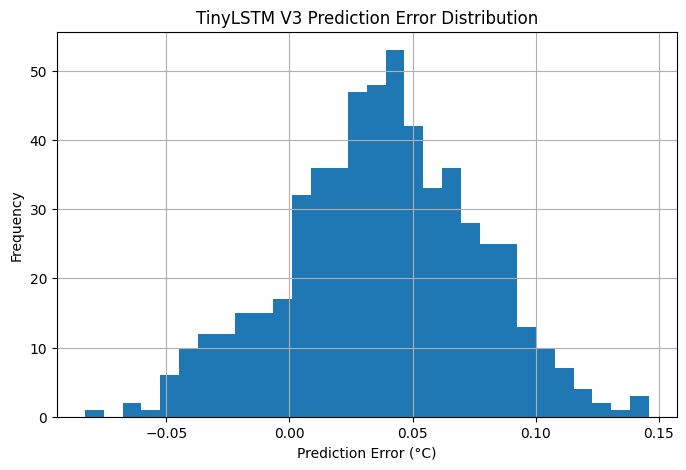

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.title("TinyLSTM V3 Prediction Error Distribution")
plt.xlabel("Prediction Error (°C)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

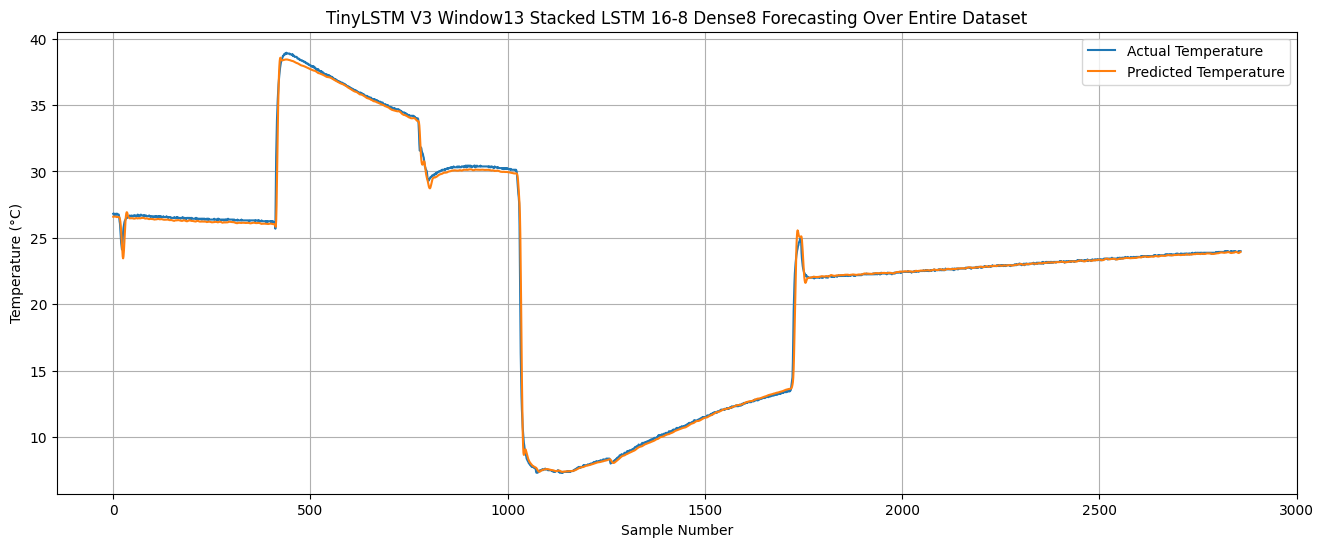

In [17]:
y_all_pred_scaled = model.predict(X, verbose=0)

y_all_actual = scaler.inverse_transform(y)
y_all_pred = scaler.inverse_transform(y_all_pred_scaled)

plt.figure(figsize=(16, 6))

plt.plot(y_all_actual, label="Actual Temperature")
plt.plot(y_all_pred, label="Predicted Temperature")

plt.title("TinyLSTM V3 Window13 Stacked LSTM 16-8 Dense8 Forecasting Over Entire Dataset")
plt.xlabel("Sample Number")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()

# window size = 10

In [18]:
WINDOW = 10

X = []
y = []

for i in range(len(temps_scaled) - WINDOW):
    X.append(temps_scaled[i:i+WINDOW])
    y.append(temps_scaled[i+WINDOW])

X = np.array(X)
y = np.array(y)

In [19]:
model = Sequential([
    Input(shape=(WINDOW, 1)),

    LSTM(16, return_sequences=True),
    LSTM(8),

    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

In [20]:
model.summary()
print("Total Parameters:", model.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 10, 16)         │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8)              │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,033 (7.94 KB)

 Trainable params: 2,033 (7.94 KB)

 Non-trainable params: 0 (0.00 B)

Total Parameters: 2033


In [21]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - loss: 0.0451 - mae: 0.1252 - val_loss: 2.4494e-05 - val_mae: 0.0048
Epoch 2/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0012 - mae: 0.0147 - val_loss: 2.0587e-06 - val_mae: 0.0012
Epoch 3/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0011 - mae: 0.0141 - val_loss: 1.7347e-05 - val_mae: 0.0041
Epoch 4/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0010 - mae: 0.0137 - val_loss: 5.1270e-05 - val_mae: 0.0071
Epoch 5/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 9.3228e-04 - mae: 0.0135 - val_loss: 2.2014e-05 - val_mae: 0.0046
Epoch 6/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 8.7282e-04 - mae: 0.0136 - val_loss: 7.3169e-05 - val_mae: 0.0085
Epoch 7/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 6.7345e-04 - mae: 0.0108 - val_loss: 1.3115e-05 - val_mae: 0.0035
Epoch 8/200
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 5.3714e-04 - mae: 0.0085 - val_loss: 1.5082e-06 - val_mae

In [22]:
y_pred_scaled = model.predict(X_test)

y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step


In [23]:
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual) * 100
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"MAE : {mae:.6f} °C")
print(f"MSE : {mse:.6f}")
print(f"RMSE: {rmse:.6f} °C")
print(f"MAPE: {mape:.4f} %")
print(f"R²  : {r2:.6f}")

MAE : 0.026705 °C
MSE : 0.001115
RMSE: 0.033386 °C
MAPE: 0.1136 %
R²  : 0.987919


graphs

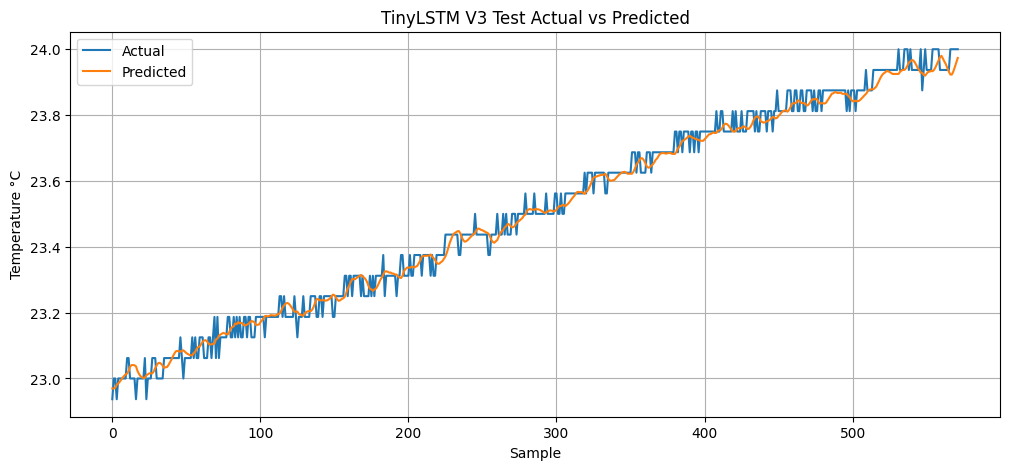

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual, label="Actual")
plt.plot(y_pred_actual, label="Predicted")

plt.title("TinyLSTM V3 Test Actual vs Predicted")
plt.xlabel("Sample")
plt.ylabel("Temperature °C")
plt.legend()
plt.grid(True)

plt.show()

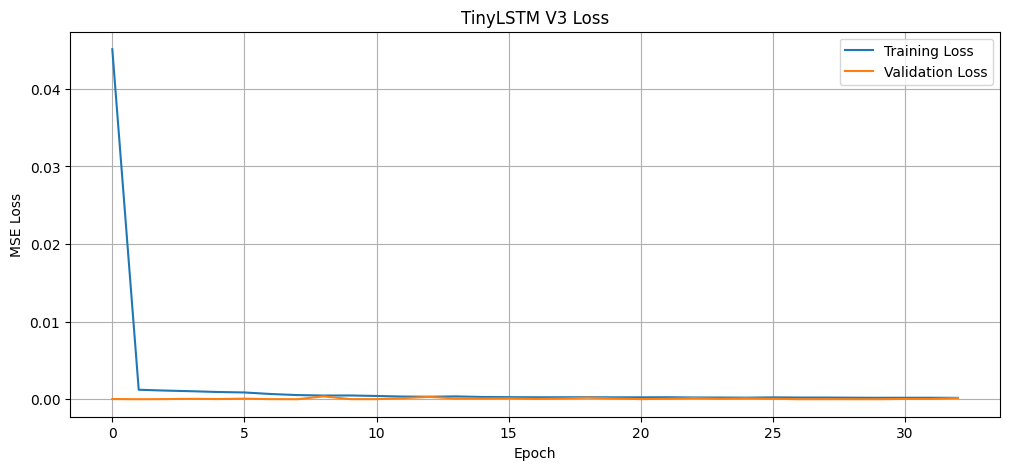

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("TinyLSTM V3 Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

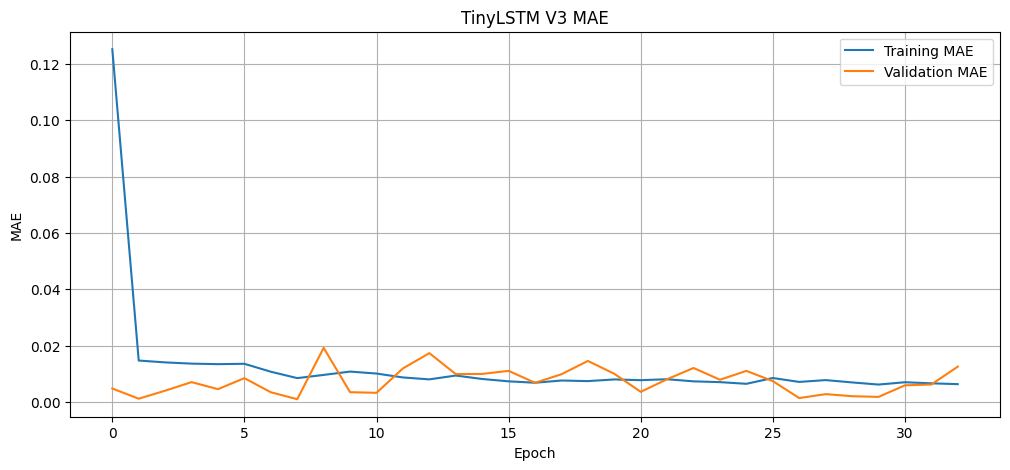

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("TinyLSTM V3 MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.show()

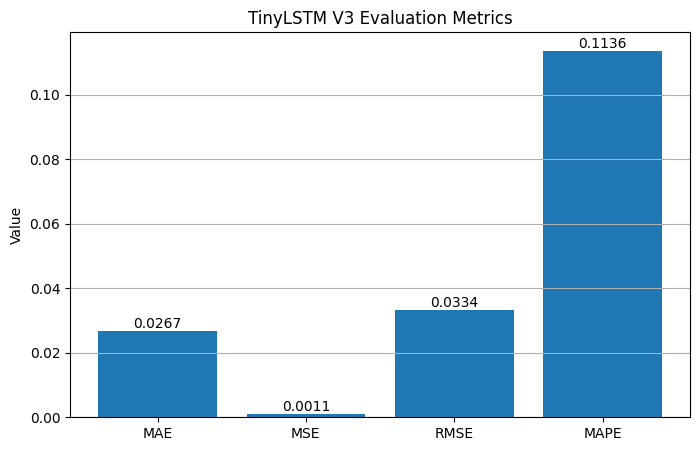

In [27]:
metric_names = ["MAE", "MSE", "RMSE", "MAPE"]
metric_values = [mae, mse, rmse, mape]

plt.figure(figsize=(8, 5))
plt.bar(metric_names, metric_values)

plt.title("TinyLSTM V3 Evaluation Metrics")
plt.ylabel("Value")
plt.grid(axis="y")

for i, v in enumerate(metric_values):
    plt.text(i, v, f"{v:.4f}", ha="center", va="bottom")

plt.show()

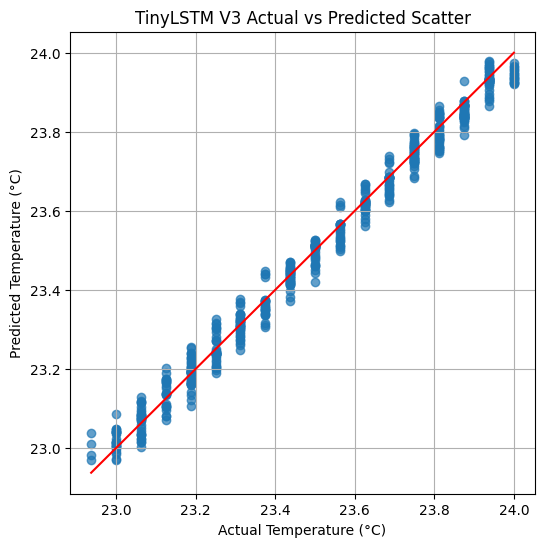

In [28]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test_actual,
    y_pred_actual,
    alpha=0.7
)

plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()],
    "r"
)

plt.title("TinyLSTM V3 Actual vs Predicted Scatter")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.grid(True)

plt.show()

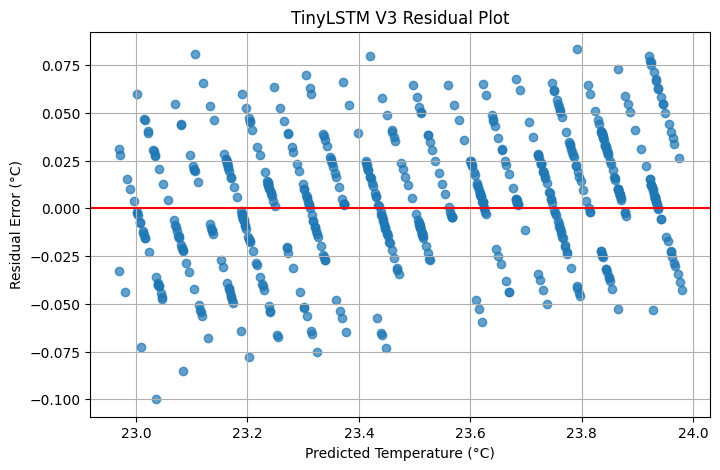

In [29]:
residuals = y_test_actual.flatten() - y_pred_actual.flatten()

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_actual,
    residuals,
    alpha=0.7
)

plt.axhline(0, color="red")

plt.title("TinyLSTM V3 Residual Plot")
plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual Error (°C)")
plt.grid(True)

plt.show()

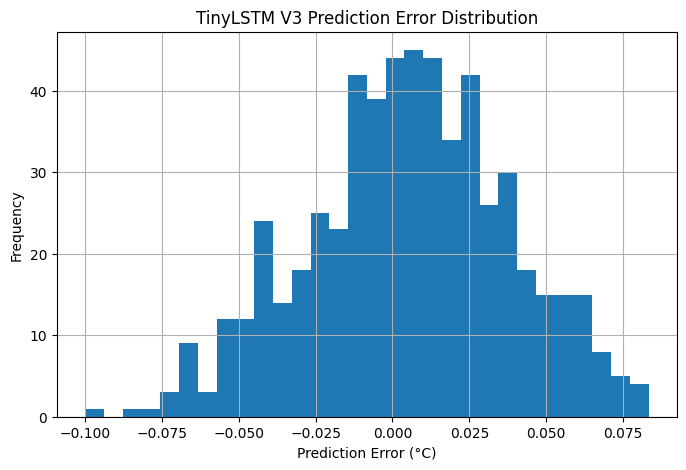

In [30]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.title("TinyLSTM V3 Prediction Error Distribution")
plt.xlabel("Prediction Error (°C)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

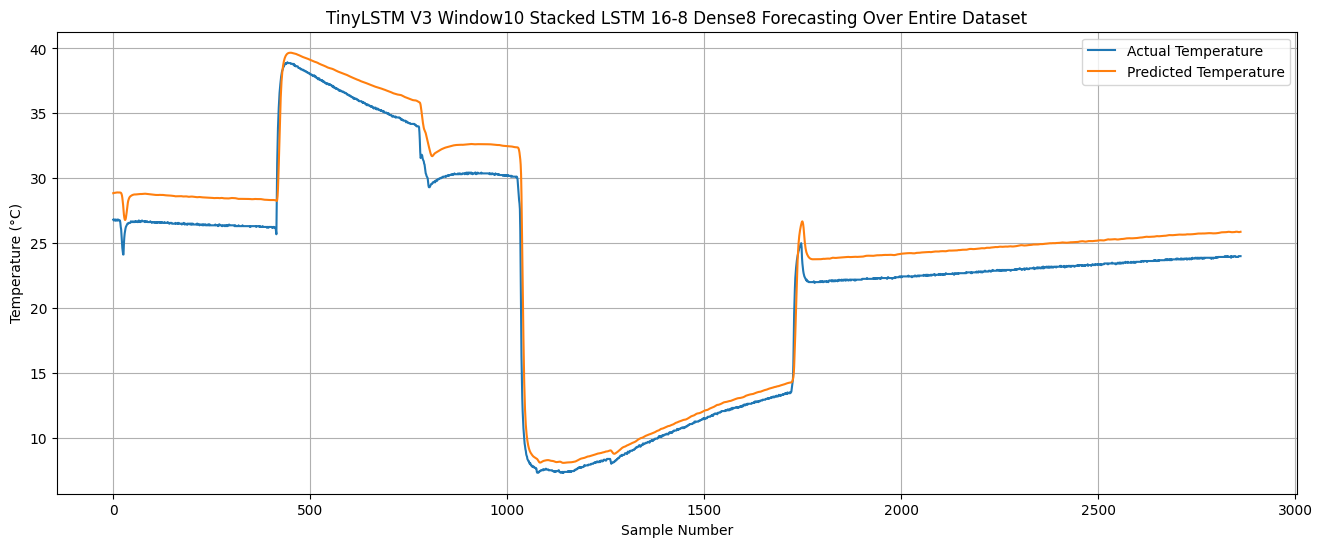

In [32]:

y_all_pred_scaled = model.predict(X, verbose=0)

y_all_actual = scaler.inverse_transform(y)
y_all_pred = scaler.inverse_transform(y_all_pred_scaled)

plt.figure(figsize=(16, 6))

plt.plot(y_all_actual, label="Actual Temperature")
plt.plot(y_all_pred, label="Predicted Temperature")

plt.title("TinyLSTM V3 Window10 Stacked LSTM 16-8 Dense8 Forecasting Over Entire Dataset")
plt.xlabel("Sample Number")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
print(y_all_actual.shape)
print(y_all_pred.shape)

(2862, 1)
(2862, 1)


In [34]:
for i in range(10):
    print(
        y_all_actual[i][0],
        y_all_pred[i][0]
    )

26.812 28.85118
26.75 28.862673
26.812 28.869442
26.812 28.874512
26.75 28.881958
26.812 28.888136
26.75 28.894932
26.812 28.899525
26.75 28.907593
26.75 28.909115


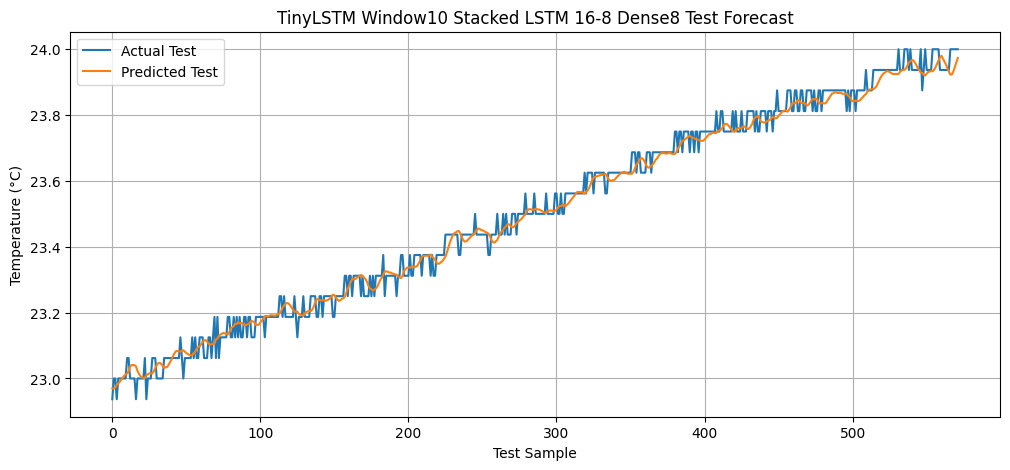

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual, label="Actual Test")
plt.plot(y_pred_actual, label="Predicted Test")

plt.title("TinyLSTM Window10 Stacked LSTM 16-8 Dense8 Test Forecast")
plt.xlabel("Test Sample")
plt.ylabel("Temperature (°C)")

plt.legend()
plt.grid(True)

plt.show()

In [36]:
full_mae = mean_absolute_error(y_all_actual, y_all_pred)
full_mse = mean_squared_error(y_all_actual, y_all_pred)
full_rmse = np.sqrt(full_mse)
full_mape = mean_absolute_percentage_error(y_all_actual, y_all_pred) * 100
full_r2 = r2_score(y_all_actual, y_all_pred)

print(f"FULL DATASET MAE : {full_mae:.6f} °C")
print(f"FULL DATASET MSE : {full_mse:.6f}")
print(f"FULL DATASET RMSE: {full_rmse:.6f} °C")
print(f"FULL DATASET MAPE: {full_mape:.4f} %")
print(f"FULL DATASET R²  : {full_r2:.6f}")

FULL DATASET MAE : 1.623373 °C
FULL DATASET MSE : 3.268176
FULL DATASET RMSE: 1.807810 °C
FULL DATASET MAPE: 7.4369 %
FULL DATASET R²  : 0.953596


In [37]:
print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 10, 16)         │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8)              │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,101 (23.84 KB)

 Trainable params: 2,033 (7.94 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,068 (15.89 KB)

None


In [38]:
for i in range(10):
    print(
        f"{i:2d}",
        y_all_actual[i][0],
        y_all_pred[i][0]
    )
    

 0 26.812 28.85118
 1 26.75 28.862673
 2 26.812 28.869442
 3 26.812 28.874512
 4 26.75 28.881958
 5 26.812 28.888136
 6 26.75 28.894932
 7 26.812 28.899525
 8 26.75 28.907593
 9 26.75 28.909115


the v2=> window=10, lastm=16 and dense=8 sinle layer (non-stacked) is the best. the last v4 although has validation r2= >98.7%, it fails when run over entire dataset i.e. long range!